In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
fake_df = pd.read_csv('data/Fake.csv')
real_df = pd.read_csv('data/True.csv')

print("Shape of Fake News ",fake_df.shape)
print("Shape of Fake News ",real_df.shape)

print("fake news columns ",fake_df.columns.to_list())
print("real news coulmns ",real_df.columns.to_list())

Shape of Fake News  (23481, 4)
Shape of Fake News  (21417, 4)
fake news columns  ['title', 'text', 'subject', 'date']
real news coulmns  ['title', 'text', 'subject', 'date']


In [3]:
print("Fake News head")
display(fake_df.head())
print("Real News head")
display(real_df.head())

Fake News head


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


Real News head


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [4]:
print("Number of null elements in fake news")
print(fake_df.isnull().sum())
print("Number of null elements in real news")
print(real_df.isnull().sum())
print("Number of duplicated elements in fake news")
print(fake_df.duplicated().sum())
print("Number of duplicated elements in real news")
print(real_df.duplicated().sum())


Number of null elements in fake news
title      0
text       0
subject    0
date       0
dtype: int64
Number of null elements in real news
title      0
text       0
subject    0
date       0
dtype: int64
Number of duplicated elements in fake news
3
Number of duplicated elements in real news
206


In [5]:
print("fake news shape before drop duplicated ",fake_df.shape)
print("real news shape before drop duplicated ",real_df.shape)

fake_df = fake_df.drop_duplicates().reset_index(drop=True)
real_df = real_df.drop_duplicates().reset_index(drop=True)

print("fake news shape after drop duplicated ",fake_df.shape)
print("real news shape after drop duplicated ",real_df.shape)

print("duplication")
print("fake ",fake_df.duplicated().sum())
print("real ",real_df.duplicated().sum())


fake news shape before drop duplicated  (23481, 4)
real news shape before drop duplicated  (21417, 4)


fake news shape after drop duplicated  (23478, 4)
real news shape after drop duplicated  (21211, 4)
duplication
fake  0
real  0


In [6]:

for name, df in [("Fake", fake_df), ("Real", real_df)]:
    print(f"\n{name} News")

    print("Empty titles:",
          df["title"].fillna("").str.strip().eq("").sum())

    print("Empty text:",
          df["text"].fillna("").str.strip().eq("").sum())



Fake News
Empty titles: 0
Empty text: 630

Real News
Empty titles: 0
Empty text: 1


In [7]:

print("Before removing empty text:")
print("Fake:", len(fake_df))
print("Real:", len(real_df))

fake_df = fake_df[
    fake_df["text"].fillna("").str.strip().ne("")
].copy()

real_df = real_df[
    real_df["text"].fillna("").str.strip().ne("")
].copy()

fake_df = fake_df.reset_index(drop=True)
real_df = real_df.reset_index(drop=True)

print("\nAfter removing empty text:")
print("Fake:", len(fake_df))
print("Real:", len(real_df))


Before removing empty text:
Fake: 23478
Real: 21211

After removing empty text:
Fake: 22848
Real: 21210


In [8]:
fake_df['label']=0
real_df['label']=1

display(fake_df.head(2))
display(real_df.head(2))


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0


,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1


In [9]:
news_df = pd.concat([fake_df,real_df],ignore_index=True)

print("news shape ",news_df.shape)
print(news_df['label'].value_counts())

news shape  (44058, 5)
label
0    22848
1    21210
Name: count, dtype: int64


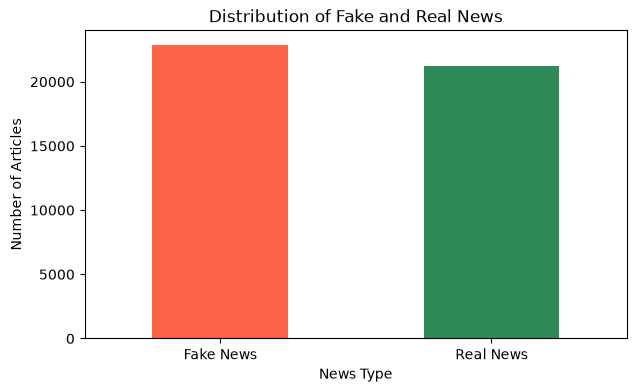

In [10]:

label_counts = news_df["label"].value_counts().sort_index()

label_counts.index = ["Fake News", "Real News"]

label_counts.plot(
    kind="bar",
    color=["tomato", "seagreen"],
    figsize=(7, 4)
)

plt.title("Distribution of Fake and Real News")
plt.xlabel("News Type")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.show()


In [11]:

news_df["title_length"] = news_df["title"].str.len()
news_df["text_length"] = news_df["text"].str.len()

print("Title length statistics:")
print(news_df["title_length"].describe())

print("\nText length statistics:")
print(news_df["text_length"].describe())


Title length statistics:
count    44058.000000
mean        79.986994
std         25.364962
min          8.000000
25%         63.000000
50%         73.000000
75%         91.000000
max        286.000000
Name: title_length, dtype: float64

Text length statistics:
count    44058.000000
mean      2502.418131
std       2168.849328
min          5.000000
25%       1291.000000
50%       2206.000000
75%       3122.000000
max      51794.000000
Name: text_length, dtype: float64


In [12]:

fake_titles = set(
    news_df.loc[news_df["label"] == 0, "title"].str.strip().str.lower()
)

real_titles = set(
    news_df.loc[news_df["label"] == 1, "title"].str.strip().str.lower()
)

common_titles = fake_titles.intersection(real_titles)

print("Number of titles appearing in both classes:",
      len(common_titles))


Number of titles appearing in both classes: 0


In [13]:
from sklearn.model_selection import train_test_split

x = news_df['text']
y = news_df['label']

X_train, X_test, y_train, y_test = train_test_split(x,y,random_state=42,test_size=0.2,stratify=y)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training samples: 35246
Testing samples: 8812

Training label distribution:
label
0    18278
1    16968
Name: count, dtype: int64

Testing label distribution:
label
0    4570
1    4242
Name: count, dtype: int64


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

In [15]:
x_train_tfidf = tfidf.fit_transform(X_train)

In [16]:
x_test_tfidf = tfidf.transform(X_test)

In [17]:
print(x_train_tfidf.shape)

print(x_test_tfidf.shape)

(35246, 111435)
(8812, 111435)


In [18]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

In [19]:
model.fit(x_train_tfidf,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [20]:
y_pred = model.predict(x_test_tfidf)

In [21]:
print(y_pred[:10])

[1 1 0 0 0 1 0 0 1 1]


In [22]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [23]:
accuracy = accuracy_score(y_test,y_pred)
print(accuracy)
print(classification_report(y_test,y_pred))

0.9883113935542442
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4570
           1       0.99      0.99      0.99      4242

    accuracy                           0.99      8812
   macro avg       0.99      0.99      0.99      8812
weighted avg       0.99      0.99      0.99      8812



In [24]:
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[4509   61]
 [  42 4200]]


In [25]:
y_train_pred = model.predict(x_train_tfidf)
train_accuracy = accuracy_score(y_train,y_train_pred)

print("test accuracy ",accuracy)
print("training accuracy ",train_accuracy)

test accuracy  0.9883113935542442
training accuracy  0.9914316518186461


In [26]:
print(type(X_train))
print(X_train.iloc[0] if hasattr(X_train, "iloc") else X_train[0])

<class 'pandas.Series'>
A Louisiana state representative introduced legislation that would ban strippers who are over the age of 28 or who weigh more than 160 pounds.According to local news reports Rep. Kenneth Havard, a Republican representing Jackson, introduced the legislation in response to an earlier measure which would prevent strip clubs from hiring women under the age of 21.Havard proposed an amendment to the bill, imposing age and weight restrictions for women working as strippers in the state.Many of the state s male lawmakers responded to Havard s bill with disturbingly sexist actions and comments.Several male lawmakers can be seen on this video tossing around dollar bills, while others can be heard laughing at the proposal.After coming under fire from Rep Nancy Landry, who asked if the amendment was meant to imply that women over a certain age or weight were not fit to dance, Havard replied that he was just trying to make sure they don t hurt each other.When asked if he bel

In [27]:
def predict_news(news_text):
    news_tfidf = tfidf.transform([news_text])
    prediction = model.predict(news_tfidf)

    if prediction[0] == 0:
        return "Fake News"
    else:
        return "Real News"

In [28]:
news_detiction = input("Enter news to detict ")
print(predict_news(news_detiction))



Fake News


In [29]:
import joblib

joblib.dump(model,"Fake news model.pk1")
joblib.dump(tfidf,"TFIDF vectorizer.pk1")

['TFIDF vectorizer.pk1']

In [30]:
loaded_model = joblib.load("Fake news model.pk1")
loaded_tfidf = joblib.load("TFIDF vectorizer.pk1")

In [34]:
news_text = input("Enter your text")

news_tfidf = loaded_tfidf.transform([news_text])
news_model = loaded_model.predict(news_tfidf)

if news_model[0] == 0:
    print("Fake News")
else:
    print("Real News")

Real News
